# Infer CNV on lung cancer dataset

In this tutorial, we infer copy number variation (CNV) from a single-cell RNA-seq dataset and use it to tell tumor
cells from normal cells. Tumor cells often gain or lose copies of large parts of chromosomes, and the genes in a gained
region are, on average, expressed a little higher, while the genes in a lost region are expressed a little lower. A
single gene is too noisy to show the change, so infercnvpy averages the expression over many neighboring genes along
the genome and compares the average to normal (reference) cells. The result is an expression signal that follows copy
number, not a measurement of DNA copy number, and only changes that span a large part of a chromosome are reliable.

For this tutorial, we use the non-small cell lung cancer dataset by {cite}`Maynard2020`, with samples from several
patients, generated on the Smart-seq2 platform and downsampled to 3,000 cells. It is available through
{func}`infercnvpy.datasets.maynard2020_3k`.

```{note}
The results of infercnvpy look similar, but not identical, to those of R inferCNV.

For droplet (e.g. 10x) or imaging data with UMI counts, {func}`infercnvpy.tl.copy_number` calls copy number,
clones and aneuploid cells from the raw counts, and you don't need the threshold of the section on classifying
tumor cells below. It isn't meant for Smart-seq2 data such as this dataset. The {doc}`API page </api>` says which
function to use.
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import infercnvpy as cnv

sc.set_figure_params(figsize=(5, 5), dpi=100, ipython_format="png")

## Loading the example dataset

```{note}
**Preprocessing data**

Low-quality cells should already be filtered out and the input data
must be normalized and log-transformed. For more information, see
{ref}`input-data`.

Also, the genomic positions need to be stored in `adata.var`. The
columns `chromosome`, `start`, and `end` hold the chromosome and
the start and end positions on that chromosome for each gene,
respectively.

Infercnvpy provides the {func}`infercnvpy.io.genomic_position_from_biomart` and
{func}`infercnvpy.io.genomic_position_from_gtf` functions
to get this information online or from a GTF file and store them in `adata.var`.
```

The example dataset is already preprocessed.

In [2]:
adata = cnv.datasets.maynard2020_3k()
# the dataset spells the alveolar cell types "Alevolar"
adata.obs["cell_type"] = adata.obs["cell_type"].cat.rename_categories(lambda c: c.replace("Alevolar", "Alveolar"))
print(adata)
adata.var.loc[:, ["ensg", "chromosome", "start", "end"]].head()

AnnData object with n_obs × n_vars = 3000 × 55556
    obs: 'age', 'sex', 'sample', 'patient', 'cell_type'
    var: 'ensg', 'mito', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_counts', 'chromosome', 'start', 'end', 'gene_id', 'gene_name'
    uns: 'cell_type_colors', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap'
    obsp: 'connectivities', 'distances'
    layers: None (.X)


,ensg,chromosome,start,end
symbol,,,,
AL645933.5,ENSG00000288587.1,chr6,31400702,31463705
AC010184.1,ENSG00000288585.1,chr3,141449745,141456434
AC023296.1,ENSG00000288580.1,chr8,2923568,2926689
AL117334.2,ENSG00000288577.1,chr20,3406380,3410036
AC107294.4,ENSG00000288576.1,chr3,184778723,184780720


The UMAP plot of the transcriptomics data shows the annotated cell types:

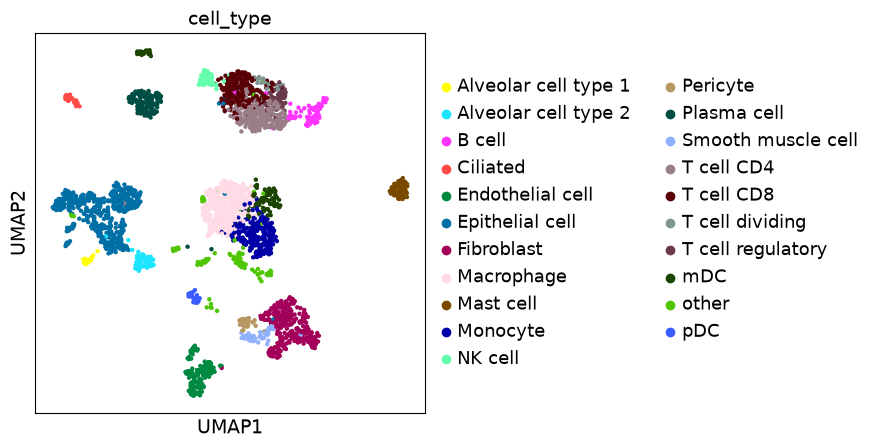

In [3]:
sc.pl.umap(adata, color="cell_type")

## Running infercnv

{func}`infercnvpy.tl.infercnv` sorts genes by chromosome and genomic position and averages their expression over
running windows of genes, relative to the reference cells. R inferCNV uses windows of about 100 genes for whole
transcriptome data. Larger windows give smoother profiles at the cost of resolution, and gene panels with few genes
per chromosome need smaller windows. Here we use 250 genes for smoother profiles, because the dataset keeps all 55,556
genes, including many that are barely expressed. The argument `min_mean` drops lowly expressed genes before the
windows are formed, and R inferCNV suggests a cutoff of 1 for Smart-seq2 and 0.1 for 10x data. By default, infercnvpy
keeps every 10th window (`step=10`), and it leaves out chrX and chrY.

{func}`~infercnvpy.tl.infercnv` adds a `cell x window` matrix to `adata.obsm["X_cnv"]`, with one column per window,
and the positions of the windows to `adata.uns["cnv"]`.

For more information about the method check out {ref}`infercnv-method`.

```{note}
**Choosing reference cells**

The most common use case is to compare tumor against normal cells. If you have
prior information about which cells are normal (e.g. from cell-type annotations
based on transcriptomics data), it is recommended to provide this information
to {func}`~infercnvpy.tl.infercnv`.

The more different cell types you
can provide, the better. Some cell types physiologically over-express
certain genomic regions (e.g. plasma cells highly express Immunoglobulin genes
which are genomically adjacent). If you provide multiple cell types,
a gene contributes to the CNV signal only if its expression lies outside the range
of the mean expressions of all provided cell types.

If you don't provide any reference, the mean of all cells is used instead, and infercnvpy
warns about it. The mean of all cells may work well on datasets that contain enough
tumor and normal cells.
```

In [4]:
# immune and stromal cell types as normal cells. Smooth muscle cells, dividing T cells, the alveolar
# and ciliated cells and "other" are not in the reference, and the classification below shows how they are called.
reference_cat = [
    "B cell",
    "Macrophage",
    "Mast cell",
    "Monocyte",
    "NK cell",
    "Plasma cell",
    "T cell CD4",
    "T cell CD8",
    "T cell regulatory",
    "mDC",
    "pDC",
    "Fibroblast",
    "Endothelial cell",
    "Pericyte",
]
cnv.tl.infercnv(adata, reference_key="cell_type", reference_cat=reference_cat, window_size=250)

Now, we can plot the CNV signal by cell type. Each row of the heatmap is a cell, and the cells are grouped by cell
type (colored bar on the left). Each column is a window of genes, ordered from chr1 to chr22, so the width of a
chromosome is its number of windows, not its length. Red marks higher expression than in the reference, which
suggests a gain, and blue marks lower expression, which suggests a loss. The color scale is centered at 0 with
separate limits for red and blue, so the same shade of red and blue can stand for different values.

Lung carcinomas arise from epithelial cells, so the tumor cells are among the cells annotated as epithelial, and the
epithelial cells show gains and losses of large genomic regions. With more cells than pixel rows in the figure, each
pixel row shows one of the cells that fall into it, and `aggregate="mean"` shows their mean instead.

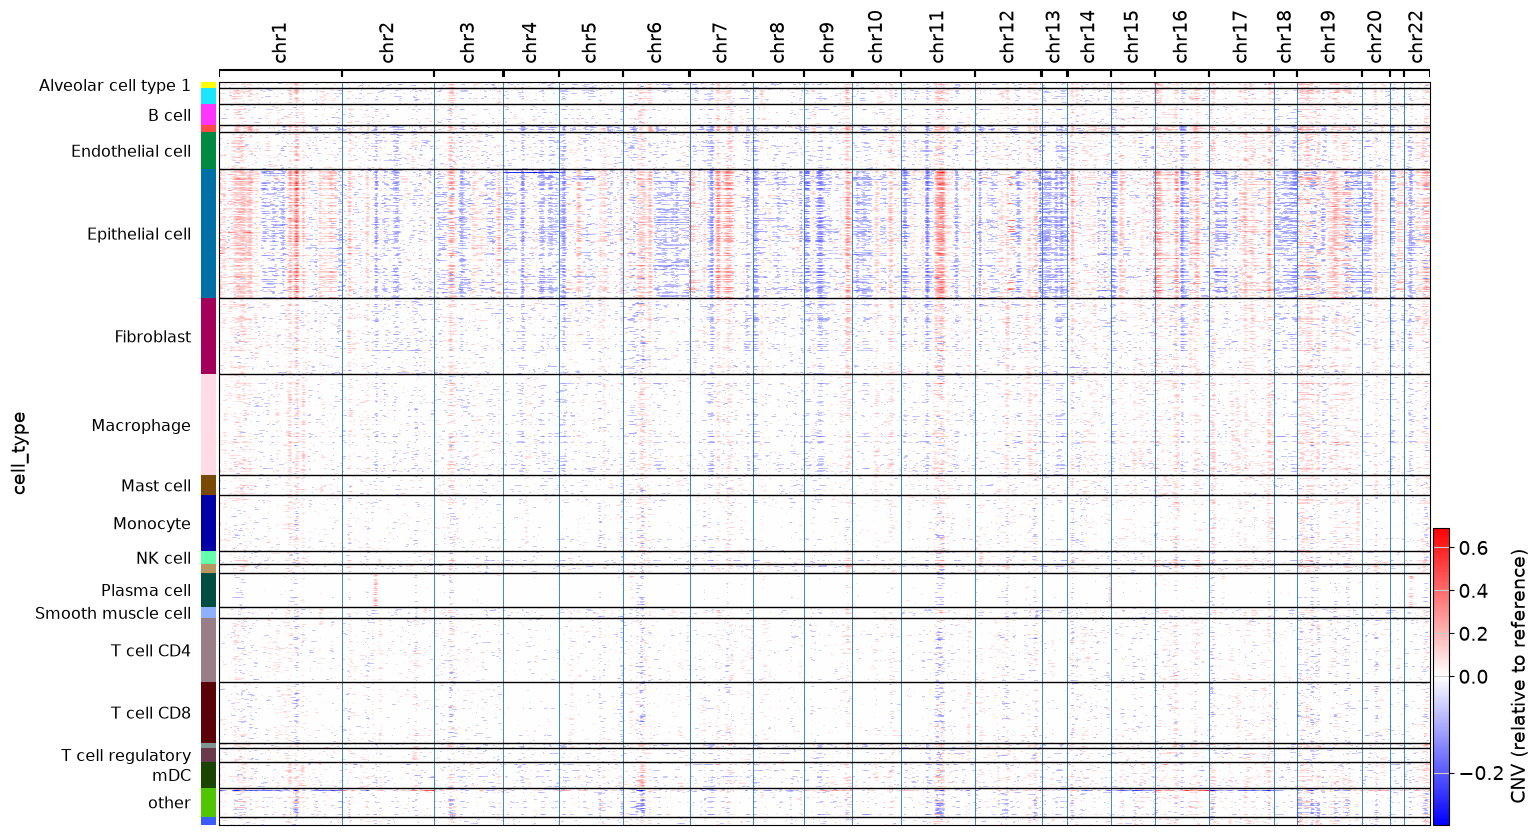

In [5]:
cnv.pl.chromosome_heatmap(adata, groupby="cell_type")

## Clustering by CNV profiles and identifying tumor cells

To cluster and annotate cells, `infercnvpy` mirrors the `scanpy` workflow.
The following functions work like their `scanpy` counterparts, except that
they use the CNV profile matrix as input. Using these functions, we can perform
graph-based clustering and generate a UMAP plot based on the CNV profiles.
Based on these clusters, we can annotate tumor and normal cells. The functions write
`adata.obsm["X_cnv_pca"]`, the `cnv_neighbors` graph, `adata.obs["cnv_leiden"]` and `adata.obsm["X_cnv_umap"]`.

```{eval-rst}
.. autosummary::

   infercnvpy.tl.pca
   infercnvpy.pp.neighbors
   infercnvpy.tl.leiden
   infercnvpy.tl.umap
   infercnvpy.pl.umap
```

In [6]:
cnv.tl.pca(adata)
cnv.pp.neighbors(adata)
cnv.tl.leiden(adata)

After the Leiden clustering, we can plot the chromosome heatmap by CNV cluster. The dendrogram on the right orders the
clusters by the similarity of their mean CNV profiles, and labels of small clusters are left out where they would
overlap. Clusters 4, 7, 9, 10, 13, 14 and 15 show the strongest gains and losses of large genomic regions, which are
likely due to copy number variation, so these clusters likely represent tumor cells. Cluster 5, which consists of
ciliated cells, also has a high score, see below. Clusters 2 and 6 show a weaker version of such a pattern, and the dendrogram puts them next to the
tumor clusters. The other clusters show less signal, apart from narrow bands such as the one on chromosome 6, lower
than in the reference in cluster 0 and higher in cluster 1, probably at the HLA genes. Normal cell types differ in the
expression of such gene clusters, so narrow bands also appear in normal cells, while a CNV spans a large region.

The cluster numbers come from this run and can change with the versions of the packages. On your own data, look for
the clusters with large gains and losses rather than for these numbers.

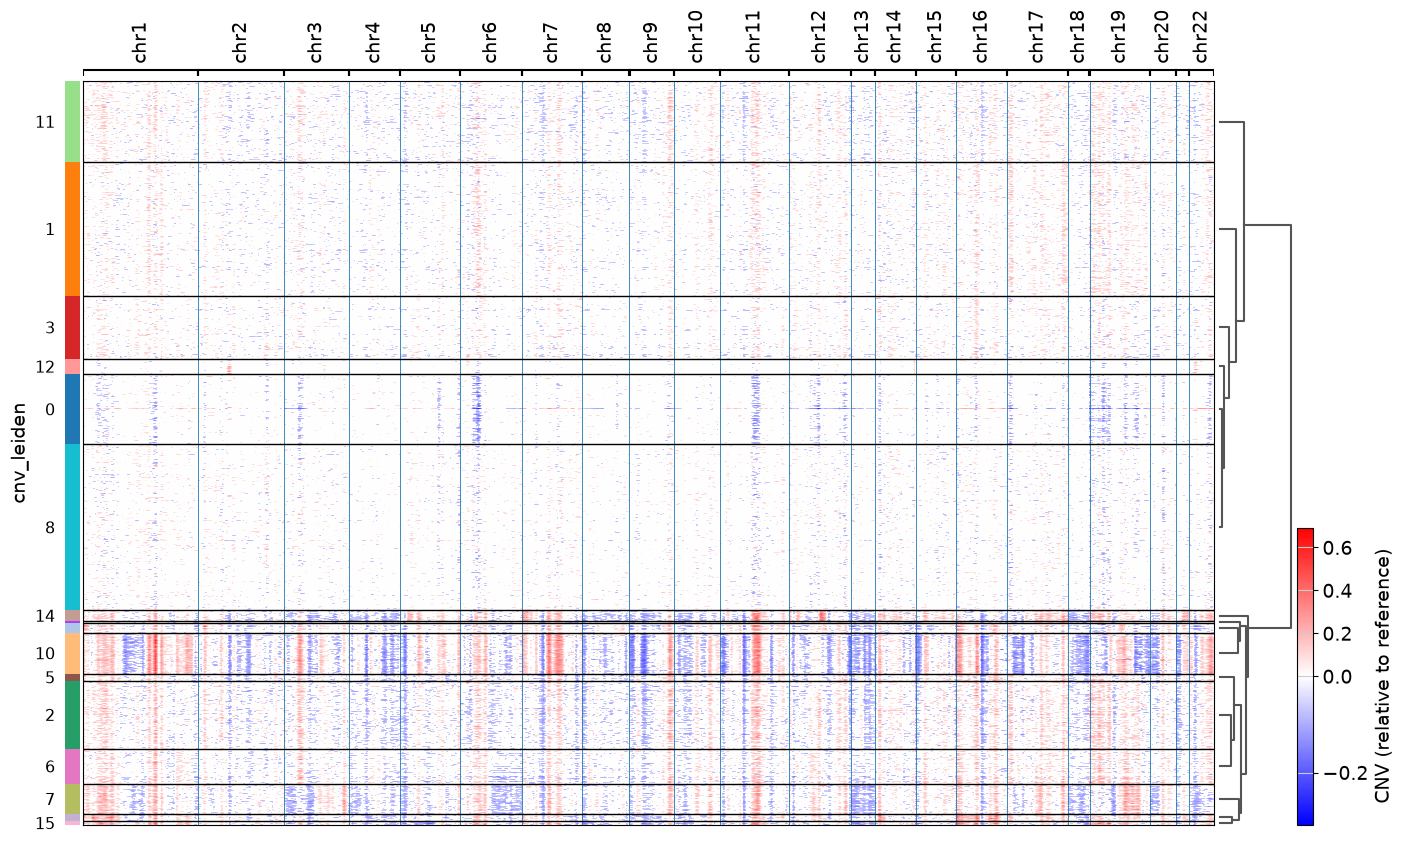

In [7]:
cnv.pl.chromosome_heatmap(adata, groupby="cnv_leiden", dendrogram=True)

### UMAP plot of CNV profiles

We can visualize the same clusters as a UMAP plot. Additionally,
{func}`infercnvpy.tl.cnv_score` computes a summary score of the CNV signal per cluster
and stores it in `adata.obs["cnv_score"]`. It is defined as the
mean of the absolute values of the CNV matrix for each cluster, so all cells of a cluster have the same score.
The score is relative, so compare it between the clusters of one dataset. There is no general cutoff.

In [8]:
cnv.tl.umap(adata)
cnv.tl.cnv_score(adata)

The UMAP plot consists of a large blob of "normal" cells and several smaller clusters with distinct CNV profiles.
Except for the ciliated cells in cluster 5, the clusters outside the blob consist of epithelial cells, and they are
likely tumor cells. The dataset holds samples of several patients, so a cluster can be the tumor of one patient or a
sub-clone, i.e. a group of cells of one tumor that share additional CNVs. The tables below the plots count the cells
of each CNV cluster per patient and per cell type.

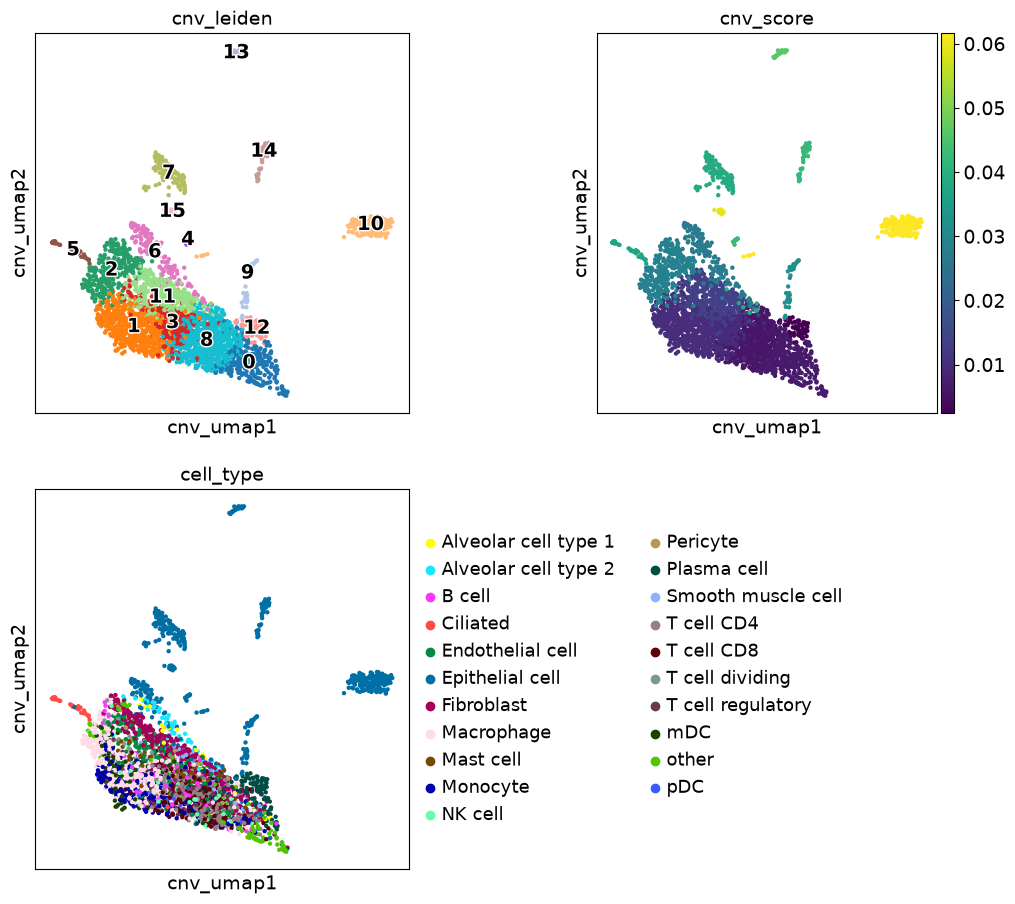

In [9]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 11), gridspec_kw={"wspace": 0.5})
ax4.axis("off")
cnv.pl.umap(
    adata,
    color="cnv_leiden",
    legend_loc="on data",
    legend_fontoutline=2,
    ax=ax1,
    show=False,
)
cnv.pl.umap(adata, color="cnv_score", ax=ax2, show=False)
cnv.pl.umap(adata, color="cell_type", ax=ax3)

In [10]:
pd.crosstab(adata.obs["patient"], adata.obs["cnv_leiden"])

cnv_leiden,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
patient,,,,,,,,,,,,,,,,
TH067,8,25,6,1,0,0,0,6,10,0,0,20,1,0,0,0
TH103,7,3,0,0,10,0,0,0,5,0,0,4,0,0,0,0
TH146,2,2,0,4,0,0,0,0,14,0,0,0,0,0,0,0
TH153,2,1,0,2,0,0,0,0,4,0,0,0,0,0,0,0
TH155,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
TH156,4,8,1,1,0,0,0,0,10,0,0,8,0,0,0,0
TH157,2,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
TH158,8,1,0,0,0,0,0,0,7,0,0,2,0,0,0,0
TH169,2,1,0,1,0,0,0,0,1,0,0,0,1,28,0,0


In [11]:
pd.crosstab(adata.obs["cell_type"], adata.obs["cnv_leiden"])

cnv_leiden,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
cell_type,,,,,,,,,,,,,,,,
Alveolar cell type 1,2,0,0,0,0,0,16,0,6,0,0,2,0,0,0,0
Alveolar cell type 2,0,2,2,0,0,0,48,0,11,0,0,2,0,0,0,0
B cell,6,22,11,16,0,0,0,0,24,0,0,2,2,0,0,0
Ciliated,0,1,0,0,0,28,0,0,0,0,0,0,0,0,0,0
Endothelial cell,8,10,26,2,0,0,1,0,36,0,0,65,0,0,0,0
Epithelial cell,9,2,3,2,10,1,73,120,10,36,166,4,1,28,41,16
Fibroblast,31,4,71,5,0,0,3,0,60,0,0,134,0,0,0,0
Macrophage,15,226,92,8,0,0,0,0,33,0,0,34,1,0,0,0
Mast cell,4,14,4,15,0,0,0,0,32,0,0,10,0,0,0,0


Most cells of each of the clusters 4, 7, 9, 10, 13, 14 and 15 come from a single patient, so these clusters are more
likely the tumors of different patients than sub-clones of one tumor. The large normal clusters, e.g. 0, 1 and 8, hold
cells of most patients and of many cell types.

We can also visualize the CNV score and clusters on the transcriptomics-based UMAP plot.
Again, subclusters of epithelial cells belong to distinct CNV clusters, and these clusters have the
highest CNV scores.

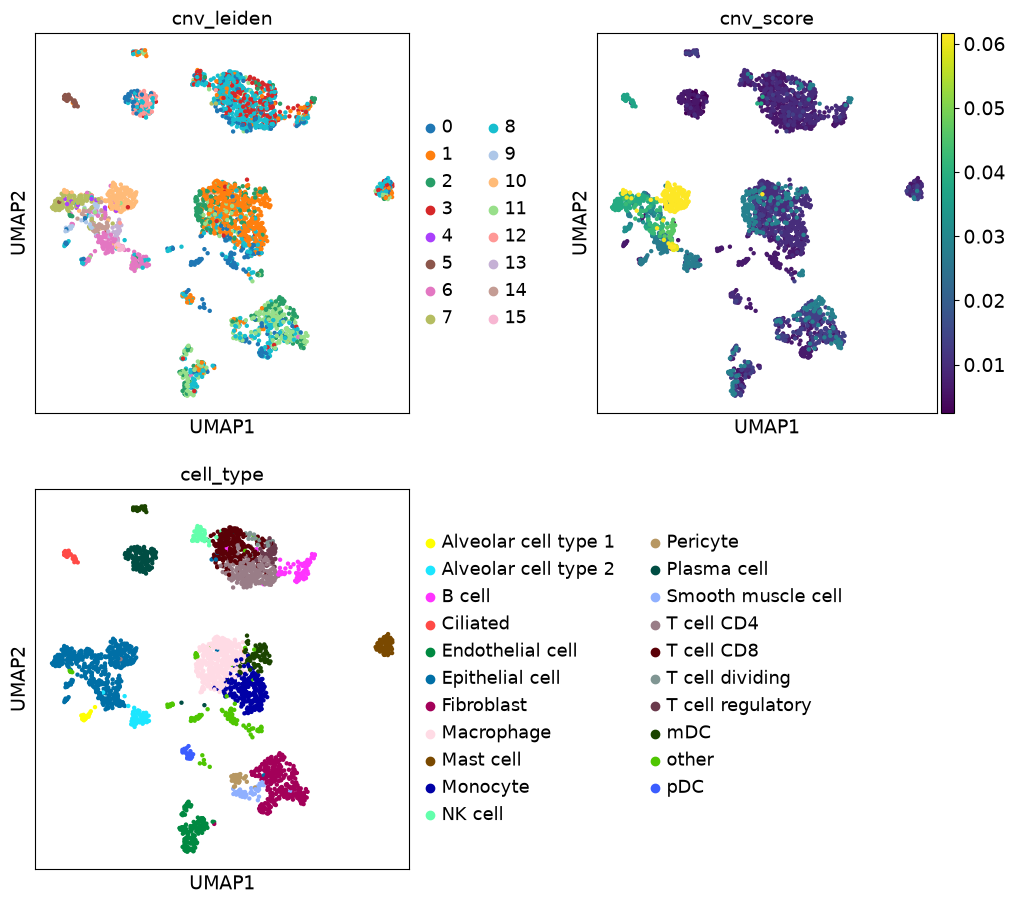

In [12]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 11), gridspec_kw={"wspace": 0.5})
ax4.axis("off")
sc.pl.umap(adata, color="cnv_leiden", ax=ax1, show=False)
sc.pl.umap(adata, color="cnv_score", ax=ax2, show=False)
sc.pl.umap(adata, color="cell_type", ax=ax3)

### Classifying tumor cells

Based on these observations, we can now assign cells to either "tumor" or "normal".
We call a CNV cluster tumor when its CNV score is above the highest score of the clusters that consist mostly of
reference cells, and store the result in a new column `cnv_status` of `adata.obs`.

The rule is a heuristic with known limits. It calls whole clusters, so the call depends on the clustering resolution,
and it needs at least one cluster that consists mostly of reference cells. Clusters with a score close to the
threshold need a look at the heatmap. Moreover, a missing CNV signal doesn't prove that a cell is normal, because
tumors with few large CNVs, and tumor cells in clusters of mostly normal cells, are called normal.

In [13]:
is_reference = adata.obs["cell_type"].isin(reference_cat)
by_cluster = pd.DataFrame(
    {
        "cnv_score": adata.obs.groupby("cnv_leiden", observed=True)["cnv_score"].first(),
        "reference_fraction": is_reference.groupby(adata.obs["cnv_leiden"], observed=True).mean(),
    }
)
threshold = by_cluster.loc[by_cluster["reference_fraction"] > 0.5, "cnv_score"].max()
tumor_clusters = by_cluster.index[by_cluster["cnv_score"] > threshold]
adata.obs["cnv_status"] = pd.Categorical(np.where(adata.obs["cnv_leiden"].isin(tumor_clusters), "tumor", "normal"))
print(by_cluster.sort_values("cnv_score").round(4))
print(f"threshold: {threshold:.4f}, tumor clusters: {list(tumor_clusters)}")
pd.crosstab(adata.obs["cell_type"], adata.obs["cnv_status"])

            cnv_score  reference_fraction
cnv_leiden                               
12             0.0025              0.9688
8              0.0058              0.9107
0              0.0064              0.7128
3              0.0095              0.9407
1              0.0099              0.9797
11             0.0137              0.8854
6              0.0271              0.0282
2              0.0282              0.8800
9              0.0319              0.0000
5              0.0370              0.0000
7              0.0387              0.0000
14             0.0421              0.0000
4              0.0424              0.0000
13             0.0463              0.0000
15             0.0596              0.0000
10             0.0617              0.0000
threshold: 0.0282, tumor clusters: ['4', '5', '7', '9', '10', '13', '14', '15']


cnv_status,normal,tumor
cell_type,,
Alveolar cell type 1,26,0
Alveolar cell type 2,65,0
B cell,83,0
Ciliated,1,28
Endothelial cell,148,0
Epithelial cell,104,418
Fibroblast,308,0
Macrophage,409,0
Mast cell,79,0


All tumor calls are epithelial or ciliated cells. The ciliated cells are most likely normal airway cells, because the
signal of their cluster is mostly narrow bands rather than gains or losses of whole chromosome arms (see the heatmap
of the tumor cells below). They aren't in the reference, though, and the score of their cluster is above the
threshold, so a threshold derived from reference cells doesn't protect against normal cell types outside the
reference. The reference also holds no epithelial cells, so gene programs specific to epithelial cells can look like
CNVs. If you know that a cell type is normal, add it to `reference_cat`. The smooth muscle cells and dividing T cells,
which aren't in the reference either, are all called normal.

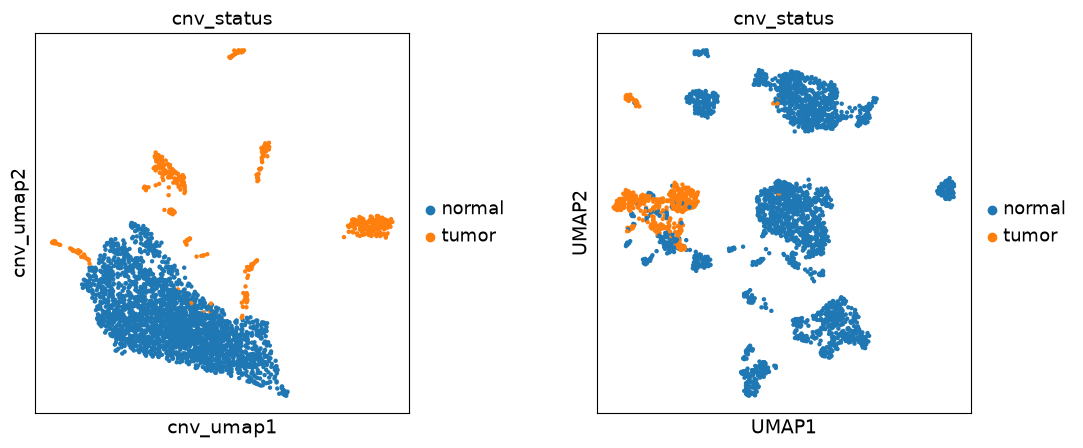

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"wspace": 0.5})
cnv.pl.umap(adata, color="cnv_status", ax=ax1, show=False)
sc.pl.umap(adata, color="cnv_status", ax=ax2)

Now, we can plot the CNV heatmap for tumor and normal cells separately, with the same color scale, so that the two
figures can be compared. Among the normal cells, clusters 2 and 6 show more CNV-like signal than the others. Cluster 6
consists mostly of epithelial and alveolar cells, and part of its cells show a broad loss at the end of chromosome 6.
Its score is just below the threshold, so it may contain tumor cells that a call per cluster misses. Most cells of
cluster 2 are reference cells, mainly macrophages and fibroblasts, and its score sets the threshold (see the table of
clusters above). Reference cells with a tumor-like pattern can be doublets of tumor and normal cells, or immune cells
that took up tumor material, rather than cells with CNVs.

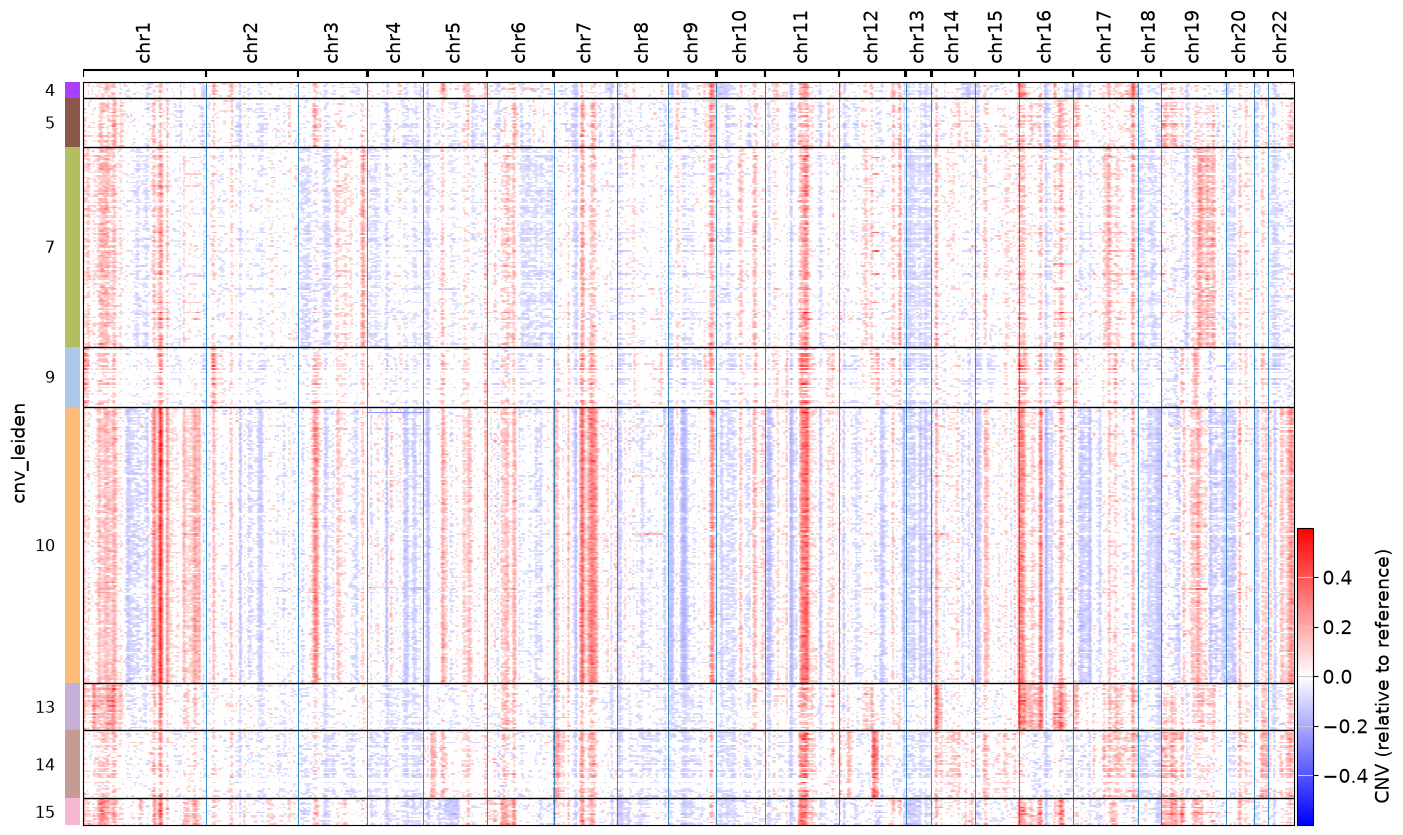

In [15]:
scale = {"groupby": "cnv_leiden", "vmin": -0.6, "vmax": 0.6}
cnv.pl.chromosome_heatmap(adata[adata.obs["cnv_status"] == "tumor", :], **scale)

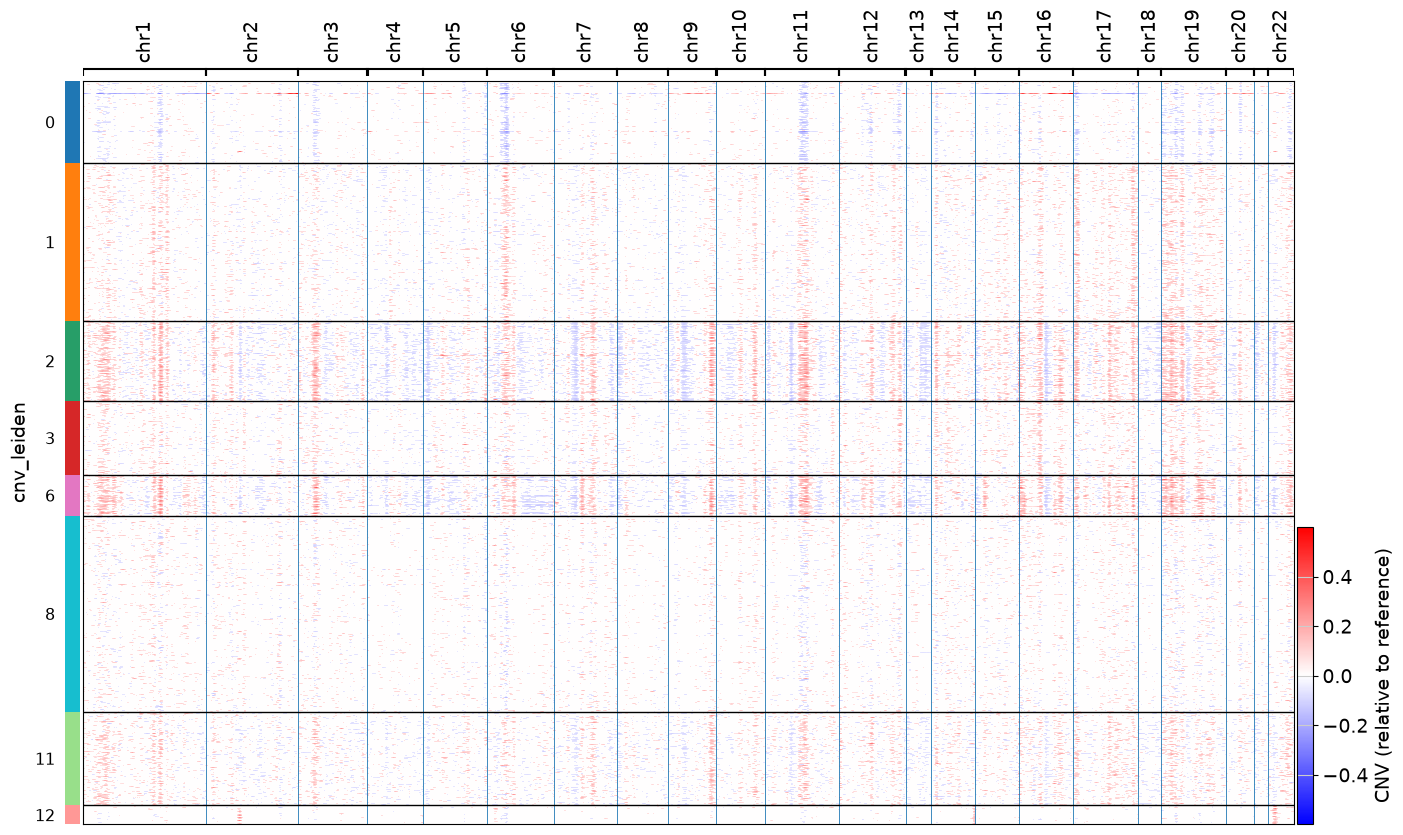

In [16]:
cnv.pl.chromosome_heatmap(adata[adata.obs["cnv_status"] == "normal", :], **scale)

## Next steps

{func}`infercnvpy.tl.ithcna` and {func}`infercnvpy.tl.ithgex` measure how much the CNV profiles and the gene
expression of the cells of a group differ. For droplet or imaging data with UMI counts, {func}`infercnvpy.tl.copy_number`
calls copy number and aneuploid cells, and the spatial tutorial shows it on Xenium data.